# FitLoop - Growth model

Monthly model: spend → signups → activation → trial → paid → churn → revenue.
Used to test the CEO's plan (double the budget) against other options.

## 1. Data
Cleaned files from `cleaning.ipynb`, loaded the same way as in `analysis.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

EXTRACTION = pd.Timestamp("2026-06-30")
PRODUCT_CHANGE = pd.Timestamp("2025-10-01")
CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "Organic", "Referral", "TikTok Ads"]
PAID_CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "TikTok Ads"]

user = pd.read_csv("../data/users_cleaned.csv").drop(columns=["Unnamed: 0"], errors="ignore")
mark = pd.read_csv("../data/marketing_spend_cleaned.csv").drop(columns=["Unnamed: 0"], errors="ignore")
for c in ["signup_date", "trial_start_date", "subscription_start_date", "subscription_end_date"]:
    user[c] = pd.to_datetime(user[c])
mark["month"] = pd.to_datetime(mark["month"])

assert len(user) == 70_237 and len(mark) == 72, "re-run cleaning.ipynb"


Helper columns. `mature` = signed up at least 14 days before extraction (enough time to pay); conversion rates use mature users only.

In [2]:
user["cohort"] = user["signup_date"].dt.to_period("M")
user["trial"] = user["trial_start_date"].notna()
user["paid"] = user["subscription_start_date"].notna()
user["churned"] = user["subscription_end_date"].notna()
user["period"] = np.where(user["signup_date"] >= PRODUCT_CHANGE, "post", "pre")
user["mature"] = user["signup_date"] <= pd.Timestamp("2026-06-16")
user["paid_days"] = (user["subscription_end_date"].fillna(EXTRACTION) - user["subscription_start_date"]).dt.days

mature = user[user["mature"]]

MONTHS = pd.period_range("2025-01", "2026-06", freq="M")
spend = (mark.assign(month=mark["month"].dt.to_period("M"))
             .pivot(index="month", columns="channel", values="spend_eur").reindex(MONTHS)[PAID_CHANNELS])
signups = (user.pivot_table(index="cohort", columns="channel", values="user_id", aggfunc="count")
               .reindex(MONTHS).fillna(0)[CHANNELS])

## 2. Parameters
All model rates in one dict, computed from the data. Scenarios only change `PARAMS`.

- Activation is split pre/post 1 Oct 2025 (the product change raised it).
- Trial and trial → paid are split by activated / not activated. Trial → paid did not change after 1 Oct, so both periods are pooled.
- Annual renewal is one value for all channels (only 298 renewals observed).
- Revenue: monthly plan €9.99 each month; annual plan €59.99 at start and at each renewal.

In [3]:
t = mature[mature["trial"]]
print("trial -> paid by period:")
print(t.pivot_table(index="period", columns="activated_d7", values="paid", aggfunc="mean").round(3))

payers = user[user["paid"]]
monthly_subs = payers[payers["plan"] == "monthly"]
annual = payers[payers["plan"] == "annual"]
renewal_due = annual[annual["subscription_start_date"] <= pd.Timestamp("2025-06-30")]

def churn_rate(d):  # cancellations per subscriber-month observed (same as analysis.ipynb)
    return d["churned"].sum() / (d["paid_days"].sum() / 30.44)

rates = pd.DataFrame({
    "act_pre":        mature[mature["period"] == "pre"].groupby("channel")["activated_d7"].mean(),
    "act_post":       mature[mature["period"] == "post"].groupby("channel")["activated_d7"].mean(),
    "trial_act":      mature[mature["activated_d7"] == 1].groupby("channel")["trial"].mean(),
    "trial_noact":    mature[mature["activated_d7"] == 0].groupby("channel")["trial"].mean(),
    "paid_act":       t[t["activated_d7"] == 1].groupby("channel")["paid"].mean(),
    "paid_noact":     t[t["activated_d7"] == 0].groupby("channel")["paid"].mean(),
    "annual_share":   payers.groupby("channel")["plan"].apply(lambda s: (s == "annual").mean()),
    "monthly_churn":  monthly_subs.groupby("channel")[["churned", "paid_days"]].apply(churn_rate),
}).loc[CHANNELS]

PARAMS = {
    "rates": rates,
    "annual_renewal": 1 - renewal_due["churned"].mean(),
    "price_monthly": 9.99,
    "price_annual": 59.99,
    "act_uplift": 0.0,                          # extra activation (S3), from the month below
    "uplift_from": pd.Period("2026-07", "M"),
}
print(f"annual renewal: {PARAMS['annual_renewal']:.1%}")
rates.round(3)

trial -> paid by period:
activated_d7      0      1
period                    
post          0.156  0.437
pre           0.163  0.442
annual renewal: 54.4%


,act_pre,act_post,trial_act,trial_noact,paid_act,paid_noact,annual_share,monthly_churn
channel,,,,,,,,
Google Ads,0.348,0.516,0.577,0.108,0.506,0.187,0.255,0.088
Influencers,0.243,0.331,0.604,0.094,0.366,0.150,0.229,0.128
Meta Ads,0.300,0.431,0.599,0.099,0.447,0.182,0.250,0.109
Organic,0.382,0.583,0.602,0.104,0.487,0.190,0.249,0.087
Referral,0.478,0.671,0.605,0.096,0.572,0.222,0.235,0.070
TikTok Ads,0.161,0.235,0.598,0.098,0.284,0.119,0.237,0.175


Check: the funnel rates should give back the observed signup → paid rate per channel (post-Oct users).

In [4]:
r = rates
implied = r["act_post"] * r["trial_act"] * r["paid_act"] + (1 - r["act_post"]) * r["trial_noact"] * r["paid_noact"]
observed = mature[mature["period"] == "post"].groupby("channel")["paid"].mean()
pd.DataFrame({"implied": implied, "observed": observed}).round(3)

,implied,observed
channel,,
Google Ads,0.161,0.158
Influencers,0.083,0.086
Meta Ads,0.126,0.129
Organic,0.179,0.175
Referral,0.239,0.248
TikTok Ads,0.049,0.049


## 3. Spend → signups
For Google, Meta and TikTok we fit `signups = a · spend^b` on monthly data (log-log regression).
`b < 1` means diminishing returns: doubling spend gives less than double the signups.
Months with no spend (TikTok before Jun 2025) and Meta Aug 2025 (spend unknown) are left out.

In [5]:
import statsmodels.api as sm

curves = {}
for ch in ["Google Ads", "Meta Ads", "TikTok Ads"]:
    d = pd.DataFrame({"spend": spend[ch], "signups": signups[ch]}).dropna()
    d = d[d["spend"] > 0]
    fit = sm.OLS(np.log(d["signups"]), sm.add_constant(np.log(d["spend"]))).fit()
    lo, hi = fit.conf_int().loc["spend"]
    curves[ch] = {"a": np.exp(fit.params["const"]), "b": fit.params["spend"],
                  "b_low": lo, "b_high": hi, "r2": fit.rsquared, "n": len(d),
                  "spend_min": d["spend"].min(), "spend_max": d["spend"].max()}

curves_tbl = pd.DataFrame(curves).T
curves_tbl["signups_if_spend_x2"] = 2 ** curves_tbl["b"]
curves_tbl.round(2)

,a,b,b_low,b_high,r2,n,spend_min,spend_max,signups_if_spend_x2
Google Ads,0.31,0.94,0.79,1.09,0.92,18.0,1910.0,4280.0,1.92
Meta Ads,3.90,0.65,0.59,0.70,0.98,17.0,2970.0,10820.0,1.57
TikTok Ads,1.42,0.85,0.68,1.03,0.91,13.0,2800.0,5250.0,1.81


Influencers: only three campaigns, all €9,000, so a curve cannot be fitted. We use the average signups per euro of those campaigns (linear, `b = 1`). This is optimistic for bigger campaigns.

In [6]:
bursts = pd.DataFrame({"spend": spend["Influencers"], "signups": signups["Influencers"]})
bursts = bursts[bursts["spend"] > 0]
display(bursts)
curves["Influencers"] = {"a": bursts["signups"].sum() / bursts["spend"].sum(), "b": 1.0}

PARAMS["curves"] = {ch: {"a": c["a"], "b": c["b"]} for ch, c in curves.items()}
PARAMS["curves"]

,spend,signups
2025-03,9000.0,2527.0
2025-09,9000.0,2534.0
2026-02,9000.0,2644.0


{'Google Ads': {'a': 0.3130298670979503, 'b': 0.9401053740825263},
 'Meta Ads': {'a': 3.8986876168353266, 'b': 0.6474164331015437},
 'TikTok Ads': {'a': 1.4230124720503508, 'b': 0.8548630764288332},
 'Influencers': {'a': 0.2853703703703704, 'b': 1.0}}

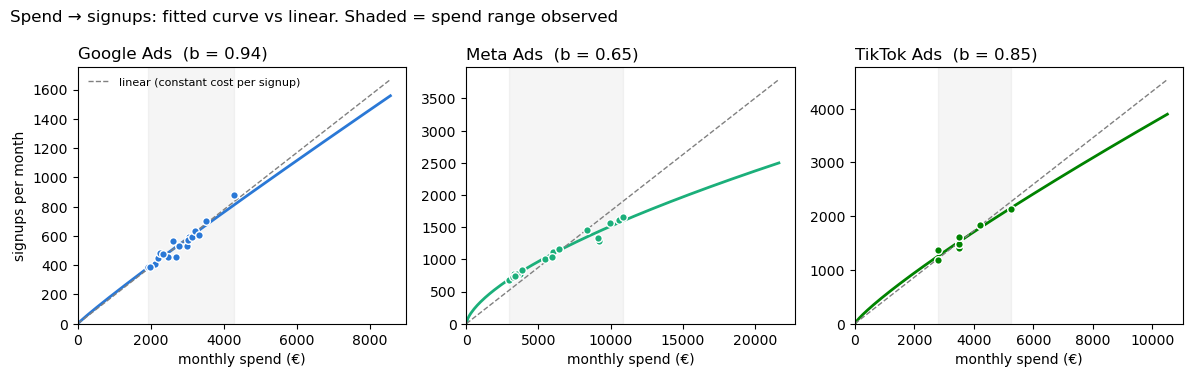

In [7]:
COLOR = {"Google Ads": "#2a78d6", "Meta Ads": "#1baf7a", "TikTok Ads": "#008300"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, ch in zip(axes, COLOR):
    c = curves[ch]
    d = pd.DataFrame({"spend": spend[ch], "signups": signups[ch]}).dropna()
    d = d[d["spend"] > 0]
    x = np.linspace(0, 2 * c["spend_max"], 200)
    ax.plot(x, c["a"] * x ** c["b"], color=COLOR[ch], lw=2)
    ax.plot(x, d["signups"].sum() / d["spend"].sum() * x, color="grey", lw=1, ls="--")
    ax.scatter(d["spend"], d["signups"], color=COLOR[ch], s=30, edgecolor="white", zorder=3)
    ax.axvspan(c["spend_min"], c["spend_max"], color="grey", alpha=0.08)
    ax.set_title(f"{ch}  (b = {c['b']:.2f})", loc="left")
    ax.set_xlabel("monthly spend (€)")
    ax.set_xlim(0)
    ax.set_ylim(0)
axes[0].set_ylabel("signups per month")
axes[0].plot([], [], color="grey", ls="--", lw=1, label="linear (constant cost per signup)")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Spend → signups: fitted curve vs linear. Shaded = spend range observed", x=0.01, ha="left")
plt.tight_layout()
plt.show()

Each dot is one month. The coloured line is the fitted curve, the dashed line is what we would get if every euro brought the same number of signups.
Meta's curve bends down: each extra euro brings fewer signups, so doubling Meta spend gives about 1.6x the signups, not 2x. Google stays close to the straight line, so it still has room to grow. TikTok is in between.
The shaded area is the spend range we have actually seen; beyond it the curve is an estimate.

## 4. Organic and Referral
These channels have no spend, so they need their own rule.

- **Organic**: a baseline that grows each month, plus a jump in January and September (New Year and back-to-school, visible in every channel).
- **Referral**: grows with the number of active subscribers at the start of the month (the referral loop).

In [8]:
active_subs = pd.Series(
    [(user["paid"] & (user["subscription_start_date"] < m.to_timestamp())
      & (user["subscription_end_date"].isna() | (user["subscription_end_date"] >= m.to_timestamp()))).sum()
     for m in MONTHS], index=MONTHS)

X_org = pd.DataFrame({"trend": np.arange(len(MONTHS)),
                      "jan_sep": [int(m.month in (1, 9)) for m in MONTHS]}, index=MONTHS)
org_fit = sm.OLS(signups["Organic"], sm.add_constant(X_org)).fit()
ref_fit = sm.OLS(signups["Referral"], sm.add_constant(active_subs.rename("active_subs"))).fit()

PARAMS["organic"] = org_fit.params.to_dict()     # const + trend * month_index + jan_sep * (Jan or Sep)
PARAMS["referral"] = ref_fit.params.to_dict()    # const + active_subs * subscribers at start of month

print(f"organic:  {org_fit.params['const']:.0f} + {org_fit.params['trend']:.1f}/month, +{org_fit.params['jan_sep']:.0f} in Jan/Sep  (R2 = {org_fit.rsquared:.2f})")
print(f"referral: {ref_fit.params['const']:.0f} + {ref_fit.params['active_subs'] * 100:.1f} per 100 active subscribers  (R2 = {ref_fit.rsquared:.2f})")

organic:  352 + 20.3/month, +221 in Jan/Sep  (R2 = 0.80)
referral: 87 + 4.1 per 100 active subscribers  (R2 = 0.92)


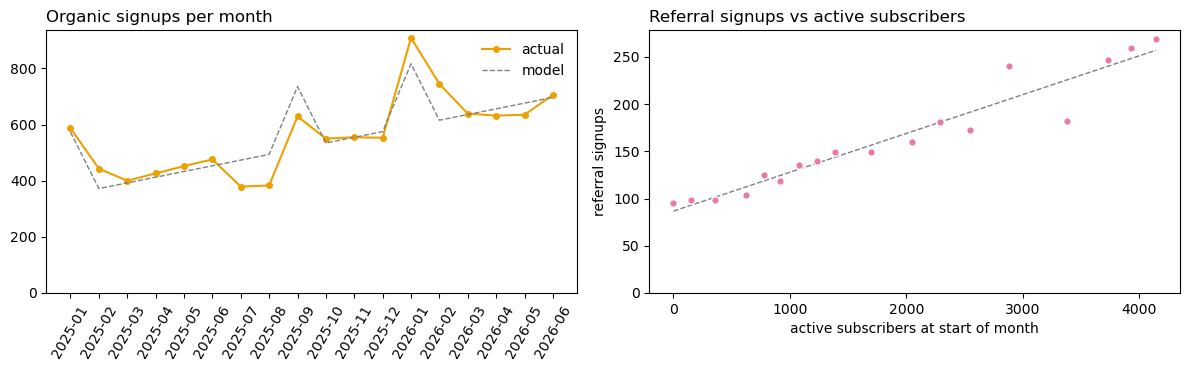

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = MONTHS.astype(str)

axes[0].plot(x, signups["Organic"], color="#eda100", marker="o", ms=4, label="actual")
axes[0].plot(x, org_fit.fittedvalues, color="grey", ls="--", lw=1, label="model")
axes[0].set_title("Organic signups per month", loc="left")
axes[0].tick_params(axis="x", rotation=60)
axes[0].legend(frameon=False)

axes[1].scatter(active_subs, signups["Referral"], color="#e87ba4", s=30, edgecolor="white", zorder=3)
xs = np.linspace(0, active_subs.max(), 50)
axes[1].plot(xs, ref_fit.params["const"] + ref_fit.params["active_subs"] * xs, color="grey", ls="--", lw=1)
axes[1].set_title("Referral signups vs active subscribers", loc="left")
axes[1].set_xlabel("active subscribers at start of month")
axes[1].set_ylabel("referral signups")

for ax in axes:
    ax.set_ylim(0)
plt.tight_layout()
plt.show()

Left: Organic grows slowly over time and jumps every January and September; the model follows this pattern well.
Right: the more paying subscribers FitLoop has, the more friends they bring, about 4 new referral signups for every 100 subscribers. This is the growth loop: more subscribers bring more referrals, who become subscribers too.
The loop is small today (under 300 signups a month) but it costs nothing.

## 5. The model
`run_model(spend_plan, PARAMS)` simulates FitLoop month by month, channel by channel:

1. **Signups**: paid channels from the spend curves, Organic from trend + Jan/Sep, Referral from last month's subscribers.
2. **New payers** = signups × (activated × trial × paid + not activated × trial × paid). Activation uses the pre/post 1 Oct 2025 rate.
3. **Plan**: a share of new payers takes the annual plan, the rest monthly.
4. **Monthly subscribers** lose `monthly_churn` each month. **Annual subscribers** renew after 12 months with `annual_renewal`.
5. **Revenue**: €9.99 per monthly subscriber per month; €59.99 for each annual subscriber at start and at each renewal (cash basis).

Simplifications: a new payer is counted in the month they signed up (payment comes about 10 days after signup); rates do not change with the size of the cohort.

Meta's spend for Aug 2025 is missing; for the simulation we use the average of July and September.

In [10]:
def run_model(spend_plan, p):
    months, r = spend_plan.index, p["rates"]
    out = {k: pd.DataFrame(0.0, index=months, columns=CHANNELS)
           for k in ["signups", "new_paid", "active_subs", "revenue"]}
    monthly_active = pd.Series(0.0, index=CHANNELS)   # monthly-plan subscribers still active
    new_annual = []                                    # new annual subscribers per month (Series by channel)

    for i, m in enumerate(months):
        # 1. signups
        s = pd.Series(0.0, index=CHANNELS)
        for ch in PAID_CHANNELS:
            s[ch] = p["curves"][ch]["a"] * spend_plan.loc[m, ch] ** p["curves"][ch]["b"]
        o = p["organic"]
        s["Organic"] = o["const"] + o["trend"] * i + o["jan_sep"] * (m.month in (1, 9))
        subs_start = out["active_subs"].iloc[i - 1].sum() if i > 0 else 0
        s["Referral"] = p["referral"]["const"] + p["referral"]["active_subs"] * subs_start

        # 2. new payers
        act = r["act_post"] if m.to_timestamp() >= PRODUCT_CHANGE else r["act_pre"]
        act = (act + p["act_uplift"] * (m >= p["uplift_from"])).clip(upper=1)
        pay_rate = act * r["trial_act"] * r["paid_act"] + (1 - act) * r["trial_noact"] * r["paid_noact"]
        paid = s * pay_rate

        # 3-4. plans and retention
        new_annual.append(paid * r["annual_share"])
        monthly_active = monthly_active * (1 - r["monthly_churn"]) + paid * (1 - r["annual_share"])
        annual_active = sum(new_annual[k] * p["annual_renewal"] ** ((i - k) // 12) for k in range(i + 1))
        annual_billed = sum(new_annual[k] * p["annual_renewal"] ** ((i - k) // 12)
                            for k in range(i + 1) if (i - k) % 12 == 0)

        # 5. revenue
        out["signups"].loc[m] = s
        out["new_paid"].loc[m] = paid
        out["active_subs"].loc[m] = monthly_active + annual_active
        out["revenue"].loc[m] = monthly_active * p["price_monthly"] + annual_billed * p["price_annual"]
    return out

In [11]:
spend_actual = spend.copy()
spend_actual.loc[pd.Period("2025-08", "M"), "Meta Ads"] = spend["Meta Ads"].loc[["2025-07", "2025-09"]].mean()

model = run_model(spend_actual, PARAMS)
pd.DataFrame({k: v.sum(axis=1) for k, v in model.items()}).round(0)

,signups,new_paid,active_subs,revenue
2025-01,2044.0,228.0,228.0,5130.0
2025-02,1687.0,187.0,399.0,5758.0
2025-03,4174.0,345.0,717.0,10261.0
2025-04,1692.0,189.0,852.0,9012.0
2025-05,1770.0,198.0,989.0,10012.0
2025-06,3378.0,264.0,1184.0,12250.0
2025-07,2995.0,243.0,1342.0,12920.0
2025-08,3211.0,264.0,1511.0,14278.0
2025-09,6908.0,518.0,1923.0,20734.0
2025-10,3754.0,420.0,2202.0,21208.0


Model totals per month with the real spend. Signups, payers, subscribers and revenue all grow, driven by more spend, the product change in Oct 2025 and the referral loop. Section 6 checks these numbers against what really happened.

## 6. Backtest
Can the model reproduce what really happened?

We **calibrate on 2025 only** (all rates, curves, Organic and Referral re-estimated with the data known on 31 Dec 2025), feed the real spend, and check the predictions for **Jan–Jun 2026**, months the model has never seen.

`fit_params(cutoff)` repeats sections 2–4 using only what was known at `cutoff`. With `cutoff = 30 Jun 2026` it gives back `PARAMS`.

One exception: no annual subscriber reached their renewal date in 2025, so the annual renewal rate (54%) is taken from the full data.

In [12]:
def fit_params(cutoff):
    u = user[user["signup_date"] <= cutoff].copy()
    seen = lambda col: u[col].where(u[col] <= cutoff)           # hide events after the cutoff
    u["trial"] = seen("trial_start_date").notna()
    u["paid"] = seen("subscription_start_date").notna()
    u["churned"] = seen("subscription_end_date").notna()
    u["paid_days"] = (seen("subscription_end_date").fillna(cutoff) - u["subscription_start_date"]).dt.days
    mat = u[u["signup_date"] <= cutoff - pd.DateOffset(days=14)]
    t = mat[mat["trial"]]
    pay = u[u["paid"]]

    rates = pd.DataFrame({
        "act_pre":       mat[mat["period"] == "pre"].groupby("channel")["activated_d7"].mean(),
        "act_post":      mat[mat["period"] == "post"].groupby("channel")["activated_d7"].mean(),
        "trial_act":     mat[mat["activated_d7"] == 1].groupby("channel")["trial"].mean(),
        "trial_noact":   mat[mat["activated_d7"] == 0].groupby("channel")["trial"].mean(),
        "paid_act":      t[t["activated_d7"] == 1].groupby("channel")["paid"].mean(),
        "paid_noact":    t[t["activated_d7"] == 0].groupby("channel")["paid"].mean(),
        "annual_share":  pay.groupby("channel")["plan"].apply(lambda s: (s == "annual").mean()),
        "monthly_churn": pay[pay["plan"] == "monthly"].groupby("channel")[["churned", "paid_days"]].apply(churn_rate),
    }).loc[CHANNELS]

    ms = MONTHS[MONTHS.to_timestamp() <= cutoff]
    curves = {}
    for ch in ["Google Ads", "Meta Ads", "TikTok Ads"]:
        d = pd.DataFrame({"spend": spend.loc[ms, ch], "signups": signups.loc[ms, ch]}).dropna()
        d = d[d["spend"] > 0]
        f = sm.OLS(np.log(d["signups"]), sm.add_constant(np.log(d["spend"]))).fit()
        curves[ch] = {"a": np.exp(f.params["const"]), "b": f.params["spend"]}
    b = spend.loc[ms, "Influencers"] > 0
    curves["Influencers"] = {"a": signups.loc[ms, "Influencers"][b].sum() / spend.loc[ms, "Influencers"][b].sum(), "b": 1.0}

    org = sm.OLS(signups.loc[ms, "Organic"], sm.add_constant(X_org.loc[ms])).fit().params.to_dict()
    ref = sm.OLS(signups.loc[ms, "Referral"], sm.add_constant(active_subs.loc[ms].rename("active_subs"))).fit().params.to_dict()

    return {**PARAMS, "rates": rates, "curves": curves, "organic": org, "referral": ref}

assert np.allclose(fit_params(EXTRACTION)["rates"], PARAMS["rates"])   # same as sections 2-4
PARAMS_2025 = fit_params(pd.Timestamp("2025-12-31"))
model_bt = run_model(spend_actual, PARAMS_2025)

Actual monthly numbers to compare with:
- new payers are counted by **signup month**, like in the model; June 2026 is left out because those users have not had time to pay yet,
- active subscribers at the end of each month,
- revenue = every payment made in the month (monthly plan every 30.44 days, annual every 365 days).

In [13]:
month_end = MONTHS.to_timestamp(how="end")
start, stop = user["subscription_start_date"], user["subscription_end_date"]

pay = user[user["paid"]]
period_days = np.where(pay["plan"] == "annual", 365, 30.44)
n_pay = np.maximum(1, np.ceil(pay["paid_days"] / period_days)).astype(int)
k = np.concatenate([np.arange(n) for n in n_pay])
pay_dates = pay["subscription_start_date"].repeat(n_pay) + pd.to_timedelta(k * period_days.repeat(n_pay), unit="D")
pay_price = np.where(pay["plan"] == "annual", PARAMS["price_annual"], PARAMS["price_monthly"]).repeat(n_pay)

actual = pd.DataFrame({
    "signups": signups.sum(axis=1),
    "new_paid": user.groupby("cohort")["paid"].sum().reindex(MONTHS),
    "active_subs": [((start <= e) & (stop.isna() | (stop > e))).sum() for e in month_end],
    "revenue": pd.Series(pay_price, index=pay_dates.dt.to_period("M").values).groupby(level=0).sum().reindex(MONTHS),
})
actual.loc[pd.Period("2026-06", "M"), "new_paid"] = np.nan
predicted = pd.DataFrame({k: v.sum(axis=1) for k, v in model_bt.items()})

train = MONTHS < pd.Period("2026-01", "M")

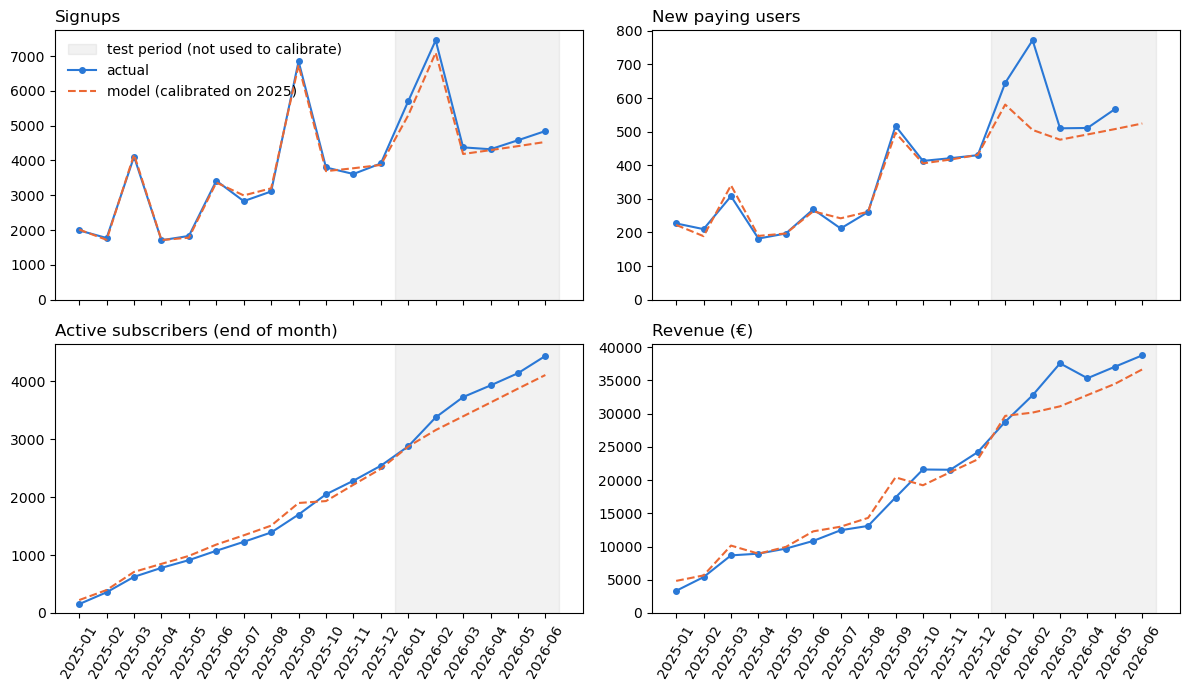

In [14]:
titles = {"signups": "Signups", "new_paid": "New paying users", "active_subs": "Active subscribers (end of month)", "revenue": "Revenue (€)"}
x = np.arange(len(MONTHS))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, c in zip(axes.flat, titles):
    ax.axvspan(11.5, len(MONTHS) - 0.5, color="grey", alpha=0.1, label="test period (not used to calibrate)")
    ax.plot(x, actual[c], color="#2a78d6", marker="o", ms=4, label="actual")
    ax.plot(x, predicted[c], color="#eb6834", ls="--", label="model (calibrated on 2025)")
    ax.set_title(titles[c], loc="left")
    ax.set_ylim(0)
    ax.set_xticks(x, MONTHS.astype(str), rotation=60)
axes[0, 0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [15]:
# error per month: + = model too high, - = model too low
err = (predicted - actual) / actual
pd.DataFrame({
    "avg error 2025 (calibration)": err[train].abs().mean(),
    "avg error 2026 (test)": err[~train].abs().mean(),
    "2026 direction": err[~train].mean(),
}).rename(index=titles).style.format({"avg error 2025 (calibration)": "{:.1%}", "avg error 2026 (test)": "{:.1%}", "2026 direction": "{:+.1%}"})

,avg error 2025 (calibration),avg error 2026 (test),2026 direction
Signups,2.4%,4.5%,-4.5%
New paying users,4.2%,13.1%,-13.1%
Active subscribers (end of month),11.4%,6.2%,-6.2%
Revenue (€),10.9%,8.0%,-6.9%


Blue is what happened, orange is what the model predicted using only 2025 data. The grey area (2026) is the test: months the model never saw.

- **Signups**: off by 4.5% on average in 2026. The spend → signups part works.
- **Subscribers and revenue**: off by 6–8% in 2026.
- **New payers**: the weakest (13%), mostly February 2026, the Influencers month.

In 2026 the model is always a bit **too low** (negative direction), so it is slightly pessimistic. That is fine for comparing scenarios: we care about the difference between options, not the exact numbers.

## 7. Scenarios for next quarter (Jul–Sep 2026)
All scenarios run the full history (real spend Jan 2025–Jun 2026) and then a different plan for Jul–Sep 2026. They use `PARAMS` calibrated on all the data.

- **Baseline**: each channel keeps its average monthly spend of Apr–Jun 2026 (no Influencers campaign, like Q2).
- **S1 – CEO plan**: double every channel.
- **S2 – TikTok → Google**: same total budget; TikTok's budget moves to Google.
- **S3 – better activation**: baseline budget; activation +4 points for new signups from July. This is the smallest effect a 4-week onboarding A/B test can detect (MDE, calculated below with 2026 traffic, 50/50 split, 5% significance, 80% power).

In [16]:
from scipy.stats import norm

recent = user[user["signup_date"] >= "2026-01-01"]
p0 = recent["activated_d7"].mean()                                   # baseline activation
per_week = len(recent) / ((recent["signup_date"].max() - recent["signup_date"].min()).days / 7)
z = norm.ppf(1 - 0.05 / 2) + norm.ppf(0.80)

for weeks in [2, 4, 6]:
    n_per_arm = per_week * weeks / 2
    print(f"{weeks} weeks: MDE = +{z * np.sqrt(2 * p0 * (1 - p0) / n_per_arm) * 100:.1f} points of activation")
print(f"(baseline activation {p0:.1%}, {per_week:,.0f} signups per week)")

2 weeks: MDE = +5.6 points of activation
4 weeks: MDE = +3.9 points of activation
6 weeks: MDE = +3.2 points of activation
(baseline activation 40.2%, 1,217 signups per week)


In [17]:
Q3 = pd.period_range("2026-07", "2026-09", freq="M")
q2_spend = spend_actual.loc["2026-04":"2026-06"].mean()

def plan(monthly):
    return pd.concat([spend_actual, pd.DataFrame([monthly] * len(Q3), index=Q3)])[PAID_CHANNELS]

s2 = q2_spend.copy()
s2["Google Ads"] += s2["TikTok Ads"]
s2["TikTok Ads"] = 0

SCENARIOS = {
    "Baseline":                 (plan(q2_spend), PARAMS),
    "S1 Double budget":         (plan(q2_spend * 2), PARAMS),
    "S2 TikTok to Google":      (plan(s2), PARAMS),
    "S3 Activation +4pp":       (plan(q2_spend), {**PARAMS, "act_uplift": 0.04}),
}
pd.DataFrame({name: sp.loc[Q3[0]] for name, (sp, _) in SCENARIOS.items()}).T.round(0)

channel,Google Ads,Influencers,Meta Ads,TikTok Ads
Baseline,3213.0,0.0,9953.0,3500.0
S1 Double budget,6427.0,0.0,19907.0,7000.0
S2 TikTok to Google,6713.0,0.0,9953.0,0.0
S3 Activation +4pp,3213.0,0.0,9953.0,3500.0


Unit economics use the same formulas as `analysis.ipynb` (section 5):
- **CAC** = paid spend ÷ new payers from paid channels,
- **LTV** per payer = monthly plan €9.99 ÷ monthly churn, annual plan €59.99 ÷ (1 − renewal), mixed by plan share,
- **payback** = CAC ÷ monthly revenue per payer.

The second table compares each scenario with the baseline.

In [18]:
r = PARAMS["rates"]
ltv = (1 - r["annual_share"]) * PARAMS["price_monthly"] / r["monthly_churn"] \
      + r["annual_share"] * PARAMS["price_annual"] / (1 - PARAMS["annual_renewal"])
rev_per_payer_month = (1 - r["annual_share"]) * PARAMS["price_monthly"] + r["annual_share"] * PARAMS["price_annual"] / 12

def summary(spend_plan, p):
    out = run_model(spend_plan, p)
    paid = out["new_paid"].loc[Q3]
    paid_ch = paid[PAID_CHANNELS].sum()
    q_spend = spend_plan.loc[Q3].sum().sum()
    cac = q_spend / paid_ch.sum()
    ltv_paid = (paid_ch * ltv[PAID_CHANNELS]).sum() / paid_ch.sum()
    return {
        "spend (€)": q_spend,
        "signups": out["signups"].loc[Q3].sum().sum(),
        "new payers": paid.sum().sum(),
        "active subs end Sep": out["active_subs"].loc[Q3[-1]].sum(),
        "revenue Q3 (€)": out["revenue"].loc[Q3].sum().sum(),
        "lifetime value of new payers (€)": (paid.sum() * ltv).sum(),
        "CAC per payer (€)": cac,
        "LTV per paid payer (€)": ltv_paid,
        "LTV/CAC": ltv_paid / cac,
        "payback (months)": cac / ((paid_ch * rev_per_payer_month[PAID_CHANNELS]).sum() / paid_ch.sum()),
    }

res = pd.DataFrame({name: summary(sp, p) for name, (sp, p) in SCENARIOS.items()})
res.round(1)

,Baseline,S1 Double budget,S2 TikTok to Google,S3 Activation +4pp
spend (€),50000.0,100000.0,50000.0,50000.0
signups,14252.9,22256.7,11543.7,14258.1
new payers,1732.1,2517.0,1808.5,1865.7
active subs end Sep,5268.6,5987.6,5353.9,5391.5
revenue Q3 (€),129725.3,152285.2,132311.0,133535.7
lifetime value of new payers (€),190156.9,269709.8,208770.8,204202.8
CAC per payer (€),45.8,53.5,42.8,42.2
LTV per paid payer (€),100.4,100.7,109.8,100.1
LTV/CAC,2.2,1.9,2.6,2.4
payback (months),5.2,6.1,4.9,4.8


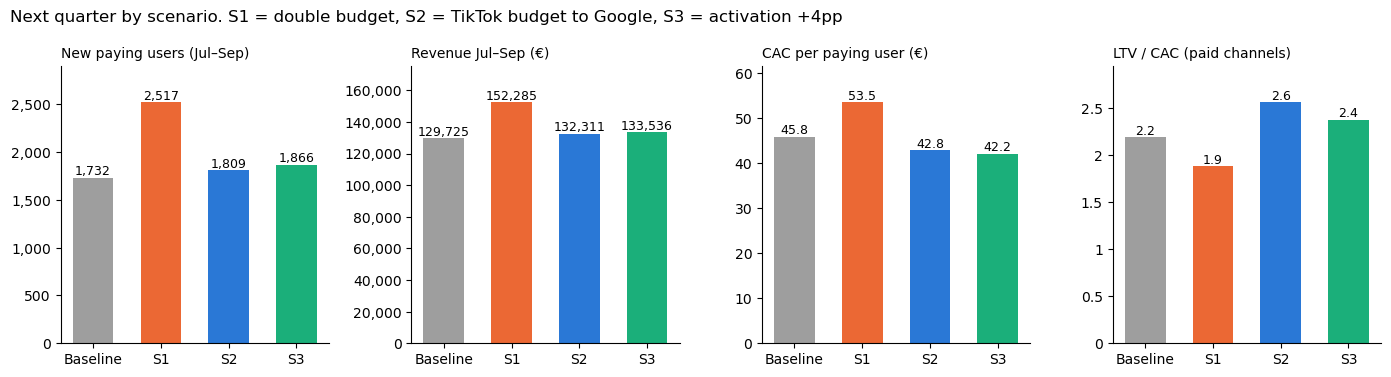

In [19]:
panels = {"new payers": "New paying users (Jul–Sep)",
          "revenue Q3 (€)": "Revenue Jul–Sep (€)",
          "CAC per payer (€)": "CAC per paying user (€)",
          "LTV/CAC": "LTV / CAC (paid channels)"}
names = list(SCENARIOS)
colors = ["#9e9e9e", "#eb6834", "#2a78d6", "#1baf7a"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (row, title) in zip(axes, panels.items()):
    v = res.loc[row, names]
    ax.bar(range(len(names)), v, color=colors, width=0.6)
    for i, val in enumerate(v):
        ax.text(i, val, f"{val:,.0f}" if val > 100 else f"{val:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks(range(len(names)), [n.split(" ", 1)[0] for n in names])
    ax.set_ylim(0, v.max() * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}" if y >= 100 else f"{y:g}")
fig.suptitle("Next quarter by scenario. S1 = double budget, S2 = TikTok budget to Google, S3 = activation +4pp", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [20]:
# each scenario minus the baseline
d = res.sub(res["Baseline"], axis=0)
vs_base = pd.DataFrame({
    "extra spend (€)": d.loc["spend (€)"],
    "extra payers": d.loc["new payers"],
    "cost per extra payer (€)": d.loc["spend (€)"] / d.loc["new payers"],
    "extra revenue Q3 (€)": d.loc["revenue Q3 (€)"],
    "extra revenue Q3 per extra € spent": d.loc["revenue Q3 (€)"] / d.loc["spend (€)"].replace(0, np.nan),
    "extra lifetime value (€)": d.loc["lifetime value of new payers (€)"],
    "lifetime value per extra € spent": d.loc["lifetime value of new payers (€)"] / d.loc["spend (€)"].replace(0, np.nan),
}).drop("Baseline")
vs_base.round(2)

,extra spend (€),extra payers,cost per extra payer (€),extra revenue Q3 (€),extra revenue Q3 per extra € spent,extra lifetime value (€),lifetime value per extra € spent
S1 Double budget,50000.0,784.88,63.7,22559.96,0.45,79552.92,1.59
S2 TikTok to Google,0.0,76.37,0.0,2585.71,NaN,18613.83,NaN
S3 Activation +4pp,0.0,133.53,0.0,3810.44,NaN,14045.87,NaN


All numbers below come from the two tables above.

**S1 – double the budget**: +785 payers, the most of all scenarios, but the extra €50,000 costs about €64 per extra payer, against a CAC of €46 in the baseline. Most of the money goes to Meta, where each extra euro brings fewer signups. In the quarter, revenue grows by about €22,600, so €0.45 for each extra euro spent. Over the payers' lifetime each extra euro brings back about €1.59, and the LTV/CAC of paid channels drops from 2.2 to 1.9.

**S2 – TikTok to Google**: no extra spend. Fewer signups, but more of them pay and they stay longer: +76 payers, CAC €43, LTV/CAC 2.6.

**S3 – activation +4 points**: no extra ad spend. +134 payers, the most of the two free options, and the lowest CAC (€42).

Limits: S1 puts Meta at about €20,000/month and S2 puts Google at about €6,700/month, both above any spend seen so far (see the spend table), so those results come from extending the curves. S3 does not include the cost of building the onboarding change.

## 8. Recommendation: where should the next euro go?
Three checks:
1. **The next euro, channel by channel**: what one extra euro brings at today's spend (slope of each curve).
2. **A combined plan**: S2 + S3 together, against the CEO's plan.
3. **Is S1 still worse if the curves are more optimistic?** We redo S1 with each `b` at the top of its 95% interval.

In [21]:
# 1. marginal return of the next euro at the Apr-Jun 2026 spend level
pay_rate = (r["act_post"] * r["trial_act"] * r["paid_act"]
            + (1 - r["act_post"]) * r["trial_noact"] * r["paid_noact"])

marg = pd.DataFrame(index=PAID_CHANNELS)
marg["spend level (€/month)"] = q2_spend.replace(0, 9000)    # Influencers: one €9,000 campaign
for ch in PAID_CHANNELS:
    a, b = PARAMS["curves"][ch]["a"], PARAMS["curves"][ch]["b"]
    marg.loc[ch, "signups per extra €100"] = 100 * a * b * marg.loc[ch, "spend level (€/month)"] ** (b - 1)
marg["payers per extra €100"] = marg["signups per extra €100"] * pay_rate[PAID_CHANNELS]
marg["cost per extra payer (€)"] = 100 / marg["payers per extra €100"]
marg["lifetime value per extra €"] = marg["payers per extra €100"] * ltv[PAID_CHANNELS] / 100
marg.sort_values("lifetime value per extra €", ascending=False).round(2)

,spend level (€/month),signups per extra €100,payers per extra €100,cost per extra payer (€),lifetime value per extra €
Google Ads,3213.33,18.14,2.92,34.30,3.43
Influencers,9000.00,28.54,2.36,42.39,2.13
TikTok Ads,3500.00,37.22,1.82,55.06,1.36
Meta Ads,9953.33,9.83,1.23,81.02,1.25


In [22]:
# 2. combined plan: TikTok budget to Google + activation +4 points
SCENARIOS["S2+S3 Combined"] = (plan(s2), {**PARAMS, "act_uplift": 0.04})
res["S2+S3 Combined"] = pd.Series(summary(*SCENARIOS["S2+S3 Combined"]))

# 3. S1 with optimistic curves: b at the top of its 95% interval, same signups at today's spend
optimistic = {**PARAMS, "curves": dict(PARAMS["curves"])}
for ch in ["Google Ads", "Meta Ads", "TikTok Ads"]:
    b_hi, c = curves_tbl.loc[ch, "b_high"], PARAMS["curves"][ch]
    optimistic["curves"][ch] = {"a": c["a"] * q2_spend[ch] ** (c["b"] - b_hi), "b": b_hi}
res["S1 optimistic curves"] = pd.Series(summary(plan(q2_spend * 2), optimistic))
res["Baseline optimistic"] = pd.Series(summary(plan(q2_spend), optimistic))

d = res.sub(res["Baseline"], axis=0)
d["S1 optimistic curves"] = res["S1 optimistic curves"] - res["Baseline optimistic"]
cols = ["S1 Double budget", "S1 optimistic curves", "S2 TikTok to Google", "S3 Activation +4pp", "S2+S3 Combined"]
pd.DataFrame({
    "extra spend (€)": d.loc["spend (€)", cols],
    "extra payers": d.loc["new payers", cols],
    "extra revenue Q3 (€)": d.loc["revenue Q3 (€)", cols],
    "extra lifetime value (€)": d.loc["lifetime value of new payers (€)", cols],
    "lifetime value per extra € spent": (d.loc["lifetime value of new payers (€)", cols] / d.loc["spend (€)", cols].replace(0, np.nan)),
    "LTV/CAC": res.loc["LTV/CAC", cols],
}).round(2)

,extra spend (€),extra payers,extra revenue Q3 (€),extra lifetime value (€),lifetime value per extra € spent,LTV/CAC
S1 Double budget,50000.0,784.88,22559.96,79552.92,1.59,1.88
S1 optimistic curves,50000.0,933.86,26826.65,94353.26,1.89,2.03
S2 TikTok to Google,0.0,76.37,2585.71,18613.83,NaN,2.56
S3 Activation +4pp,0.0,133.53,3810.44,14045.87,NaN,2.38
S2+S3 Combined,0.0,201.15,6185.25,32876.09,NaN,2.75


**The next euro.** At today's spend, an extra euro in **Google** brings back €3.43 over the payers' lifetime (€34 per extra payer). In **Meta** it brings back only €1.25 (€81 per extra payer), and TikTok €1.36. Influencers looks good (€2.13), but that number assumes a bigger campaign works as well as a €9,000 one, which we cannot check with three campaigns. LTV here is revenue, not profit, so a return close to €1 probably loses money once app-store fees and other costs are paid.

**The CEO's plan.** Doubling the budget spends half of the extra money on Meta, the channel with the lowest return. Each extra euro brings back €1.59. Even with the most optimistic curves it is €1.89, still well below what Google gives today.

**What we recommend:**
1. **Do not double the budget with the same mix.**
2. **Move TikTok's budget to Google and improve activation (S2 + S3).** With no extra ad spend this gives +201 payers and +€32,876 of lifetime value in one quarter, and LTV/CAC goes from 2.2 to 2.75.
3. **If the board wants to spend more, add it to Google in steps.** We have never seen Google above €4,280/month, so each step should be checked against CAC before the next one.
4. **Run the onboarding A/B test** (4 weeks, MDE +4 points) to confirm the activation gain before counting on it.